In [1]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


/tmp/ipykernel_3747319/3071805319.py:134: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  handles, _ = axs[3].get_legend_handles_labels()
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 

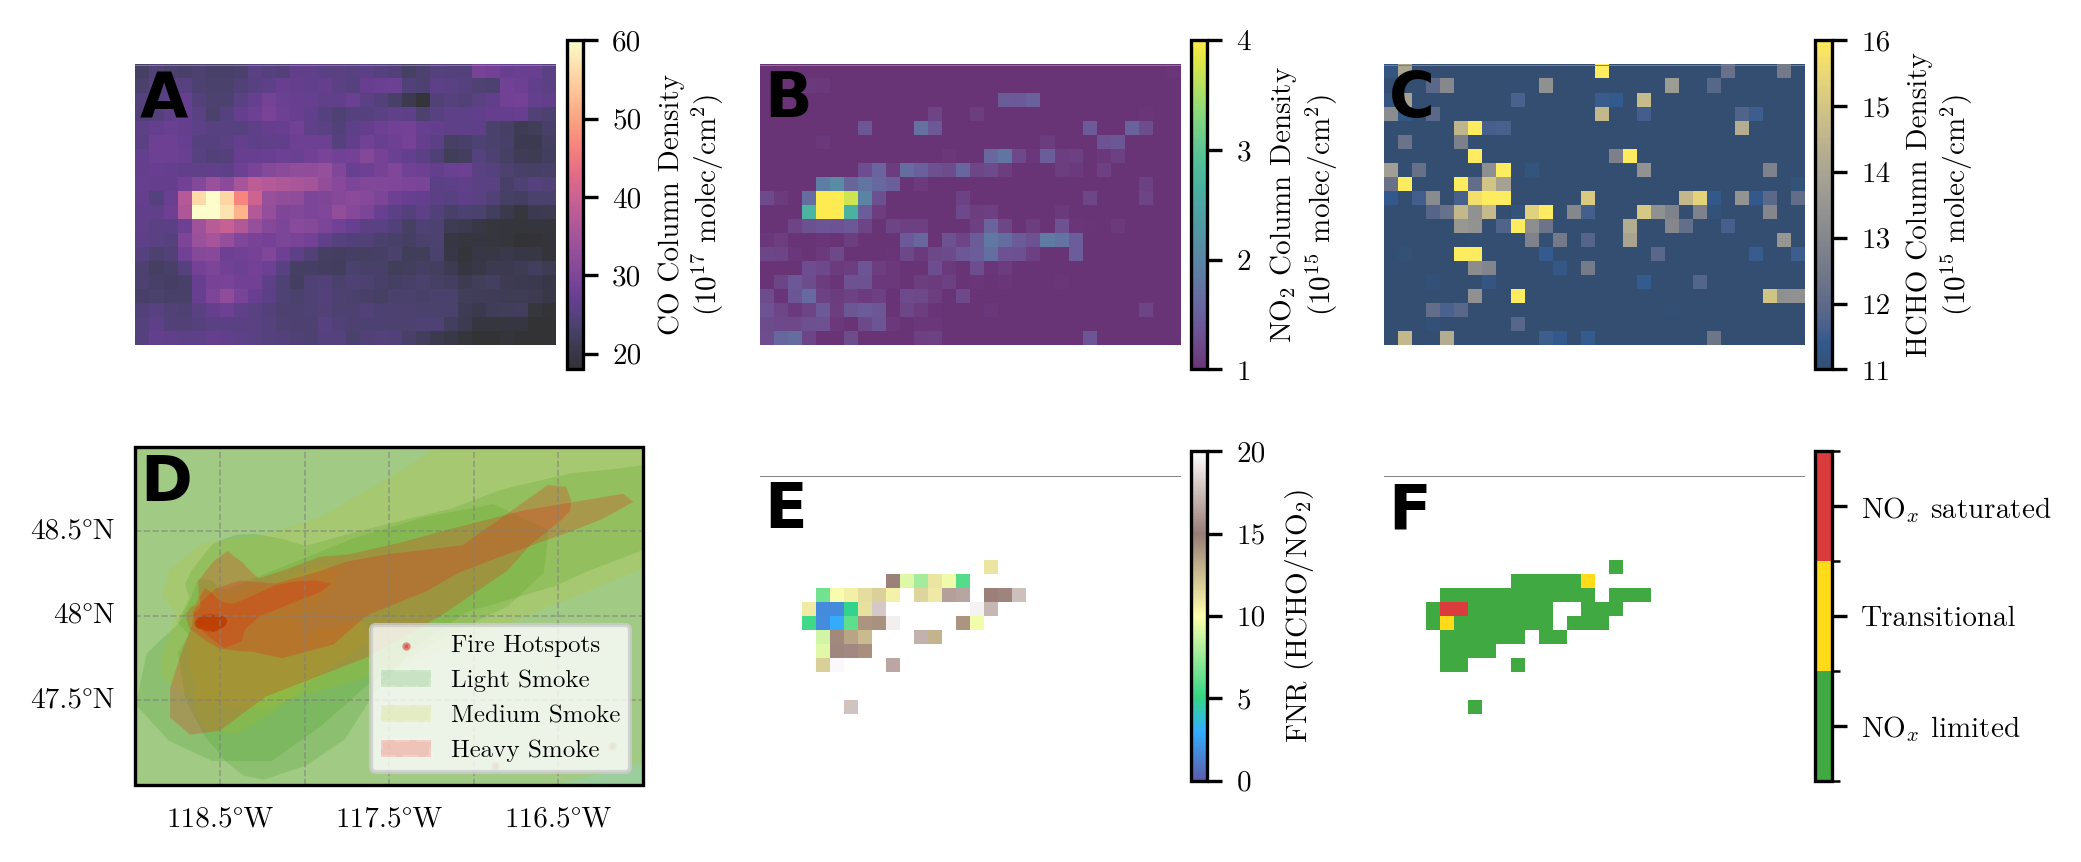

In [36]:
%matplotlib inline

from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LATITUDE_FORMATTER, LONGITUDE_FORMATTER
from matplotlib.colors import BoundaryNorm, ListedColormap

import sys
NB = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/notebooks")
CODE = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/code/airborne")
DATA = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/data")
sys.path.insert(0, str(CODE))
from fnr_threshold import make_smooth_interpolant

NC = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/data/tropomi_williams_20190803.nc")
HMS_FIRE = Path("/home/jpalmo/fs09/Datasets/NOAA_HMS/fire/hms_fire20190803.shp")
HMS_SMOKE = Path("/home/jpalmo/fs09/Datasets/NOAA_HMS/smoke/hms_smoke20190803.shp")
CO_PLUME = 3e18

ds = xr.open_dataset(NC)
co = ds["CO_column_number_density"]
no2 = ds["tropospheric_NO2_column_number_density"]
hcho = ds["tropospheric_HCHO_column_number_density"]

def as_molec(da):
    return da * (1e15 if float(np.nanmedian(da)) < 1e6 else 1.0)

co = as_molec(co)
no2 = as_molec(no2)
hcho = as_molec(hcho)
fnr = (hcho - np.nanquantile(hcho, 0.05)) / (no2 - np.nanquantile(no2, 0.05))
plume = co > CO_PLUME

age_edges = np.linspace(0, np.sqrt(10), 10) ** 2
y_edges = np.arange(0, 1.1, 0.1)
age_centers = 0.5 * (age_edges[:-1] + age_edges[1:])
y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
noxlim = np.load(DATA / "fnr_noxlim_thresholds.npz")["grid"]
noxsat = np.load(DATA / "fnr_noxsat_thresholds.npz")["grid"]
lim_of = make_smooth_interpolant(age_centers, y_centers, noxlim, smoothing=1, neighbors=20)
sat_of = make_smooth_interpolant(age_centers, y_centers, noxsat, smoothing=1, neighbors=20)

age = ds["t"].values
yhat = ds["yhat"].values
fnr_v = fnr.values
finite = (plume.values) & np.isfinite(fnr_v) & np.isfinite(age) & np.isfinite(yhat)
lim = np.full(fnr_v.shape, np.nan)
sat = np.full(fnr_v.shape, np.nan)
lim[finite] = np.asarray(lim_of(age[finite], yhat[finite])).ravel()
sat[finite] = np.asarray(sat_of(age[finite], yhat[finite])).ravel()
# 0: NOx-limited, 1: transitional, 2: NOx-saturated
regime = np.full(fnr_v.shape, np.nan)
regime[finite & (fnr_v < sat)] = 2
regime[finite & (fnr_v > lim)] = 0
regime[finite & (fnr_v >= sat) & (fnr_v <= lim)] = 1

lon, lat = np.meshgrid(ds["longitude"].values, ds["latitude"].values)
extent = [-119, -116, 47, 49]
proj = ccrs.PlateCarree()

fig, axs = plt.subplots(
    2, 3, figsize=(7, 3.5), subplot_kw={"projection": proj}, dpi=300, sharex=True, sharey=True
)
axs = axs.flatten()

countries = cfeature.NaturalEarthFeature(
    category="cultural",
    name="admin_0_countries",
    scale="50m",
    facecolor="none",
)
for ax in axs:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.add_feature(countries, edgecolor="gray", linewidth=0.2)
    ax.set_extent(extent, crs=proj)
    if ax is not axs[3]:
        ax.set_axis_off()

p = axs[0].pcolormesh(
    lon, lat, co.values / 1e17, cmap="magma", vmin=18, vmax=60, transform=proj, alpha=0.8
)
cbar = fig.colorbar(p, ax=axs[0], orientation="vertical", shrink=0.6, pad=0.02)
cbar.set_label(r"CO Column Density" + "\n" + r"($10^{17}$ molec/cm$^{2}$)", fontsize=7)
cbar.ax.tick_params(labelsize=7)

p = axs[1].pcolormesh(
    lon, lat, no2.values / 1e15, cmap="viridis", vmin=1, vmax=4, transform=proj, alpha=0.8
)
cbar = fig.colorbar(p, ax=axs[1], orientation="vertical", shrink=0.6, pad=0.02)
cbar.set_label(r"NO$_2$ Column Density" + "\n" + r"($10^{15}$ molec/cm$^{2}$)", fontsize=7)
cbar.ax.tick_params(labelsize=7)

p = axs[2].pcolormesh(
    lon, lat, hcho.values / 1e15, cmap="cividis", vmin=11, vmax=16, transform=proj, alpha=0.8
)
cbar = fig.colorbar(p, ax=axs[2], orientation="vertical", shrink=0.6, pad=0.02)
cbar.set_label(r"HCHO Column Density" + "\n" + r"($10^{15}$ molec/cm$^{2}$)", fontsize=7)
cbar.ax.tick_params(labelsize=7)

fires = gpd.read_file(HMS_FIRE)
fires = fires[fires["FRP"] > 0].to_crs(proj.proj4_init)
smoke = gpd.read_file(HMS_SMOKE).to_crs(proj.proj4_init)
fires.plot(ax=axs[3], color="tab:red", label="Fire Hotspots", alpha=0.5, markersize=1)

color_map = dict(zip(["Light", "Medium", "Heavy"], ["g", "y", "r"]))
alpha_map = dict(zip(["Light", "Medium", "Heavy"], [0.15, 0.15, 0.2]))
grouped = smoke.groupby("Density", dropna=False)
for ctype in ["Light", "Medium", "Heavy"]:
    try:
        grouped.get_group(ctype).plot(
            ax=axs[3], color=color_map[ctype], label=ctype, alpha=alpha_map[ctype], transform=proj
        )
    except KeyError:
        pass

lmark = mpatches.Patch(
    facecolor=color_map["Light"], edgecolor="white", linestyle="--", alpha=alpha_map["Light"], label="Light Smoke"
)
mmark = mpatches.Patch(
    facecolor=color_map["Medium"], edgecolor="white", linestyle="--", alpha=alpha_map["Medium"], label="Medium Smoke"
)
hmark = mpatches.Patch(
    facecolor=color_map["Heavy"], edgecolor="white", linestyle="--", alpha=alpha_map["Heavy"], label="Heavy Smoke"
)
handles, _ = axs[3].get_legend_handles_labels()
axs[3].legend(
    handles=[*handles[::-1], lmark, mmark, hmark],
    loc="lower right",
    ncol=1,
    shadow=False,
    fontsize=6,
    framealpha=0.8,
)

gl = axs[3].gridlines(
    crs=proj,
    draw_labels=True,
    linewidth=0.4,
    color="gray",
    alpha=0.6,
    linestyle="--",
    x_inline=False,
    y_inline=False,
)
gl.top_labels = False
gl.right_labels = False
gl.left_labels = True
gl.bottom_labels = True
gl.xlocator = mticker.FixedLocator(np.arange(-119, -115.5, 0.5))
gl.ylocator = mticker.FixedLocator(np.arange(47, 49.5, 0.5))
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlabel_style = {"size": 7}
gl.ylabel_style = {"size": 7}

p = axs[4].pcolormesh(
    lon, lat, fnr.where(plume).values, cmap="terrain", vmin=0, vmax=20, transform=proj, alpha=0.8
)
cbar = fig.colorbar(p, ax=axs[4], orientation="vertical", shrink=0.6, pad=0.02)
cbar.set_label(r"FNR (HCHO/NO$_2$)", fontsize=7)
cbar.ax.tick_params(labelsize=7)

cmap = ListedColormap(["tab:green", "gold", "tab:red"])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap.N)
p = axs[5].pcolormesh(lon, lat, regime, cmap=cmap, norm=norm, transform=proj, alpha=0.9)
axs[5].coastlines()
cbar = fig.colorbar(p, ax=axs[5], orientation="vertical", shrink=0.6, pad=0.02, ticks=[2, 1, 0])
cbar.ax.set_yticklabels([r"NO$_x$ saturated", "Transitional", r"NO$_x$ limited"])
cbar.ax.tick_params(labelsize=7)

for a in axs:
    a.tick_params(labelsize=12)

letters = ["A", "B", "C", "D", "E", "F"]
for letter, ax in zip(letters, axs):
    ax.text(
        0.01, 0.98, letter, color="black", transform=ax.transAxes,
        ha="left", va="top", fontsize=15, fontweight="bold", fontfamily="Arial",
    )

plt.subplots_adjust(hspace=-0.5, wspace=-0.1)
fig.tight_layout()
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/fig04.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/fig04.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
